# Test: SDO/HMI identification, September - November 2015

1. **Old and new identification.** The maps of 2015-09-01 to 2015-12-01 made by the previous script (`identification_utils.py`, path `sdo_maps`: `maps_active_2015_09_12_ccf_notnorm`) and by `sunsim.sdo` with the fixes (μ = cos θ, noise threshold scaled with the size, spots relative to the quiet Sun, days with a missing image skipped), from the same HMI images (path `sdo_data`), at the same size (1024 px, the disc cut to 944 px). Both are simulated with SunSim in the same way: filling factors, light curve and RV.
2. **Old StarSim against SunSim on the new maps.** The old StarSim (the version of the path `old_starsim`, run as in `tests/old_version`) and SunSim (`simulate_old_config`) on the same new maps and configuration: with `reproduce_old_bugs=True` they must coincide; with the physics of SunSim the differences are the known ones (projection of the pixels, spots over faculae in every pixel, MURaM limb).
3. **Time and RAM** of the two codes on these maps, each in a new process.

Configuration of the simulations: the reference of `tests/old_version` with MURaM and 2D maps (15 rings, light curve 3801-7999 Å, CCF with `HARPS_G20_mps_friendly.mas`).

In [1]:
import os, sys, time, re, subprocess, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sunsim
from sunsim import sdo, local_path, simulate_old_config

REPO = os.path.dirname(os.path.dirname(os.path.abspath(sunsim.__file__)))
sys.path.insert(0, os.path.join(REPO, 'tests', 'old_version'))
import test_old_version as tov                     # the old StarSim (work copy of 'old_starsim') and its runner

HMI = local_path('sdo_data')                       # HMI images
OLD_MAPS = local_path('sdo_maps')                  # maps of the previous script
WORK = os.path.join(REPO, 'tests', 'old_version', 'reference', 'sdo_2015')
NEW_MAPS = os.path.join(WORK, 'new_maps')
START, END = '2015-09-01', '2015-12-01'
print('old StarSim:', tov.OLD_CODE, '\nHMI images:', HMI, '\nold maps:', OLD_MAPS)

old StarSim: /Users/sophiestucki/Downloads/starsim_env/starsim 
HMI images: /Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/My Drive/storage/sdo_fits 
old maps: /Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/My Drive/storage/maps_active_2015_09_12_ccf_notnorm


## 1. The new maps

`make_sdo_maps` at 1024 px, text files (as the old StarSim reads them), the epochs numbered 0, 1, 2, ... (`epoch='index'`) as the old maps. The dates of the old maps are in their `date.txt`.

In [2]:
# local copy of the images of the period (the folder of 'sdo_data' can be a cloud folder, slow or timing out)
import shutil, glob
HMI_LOCAL = os.path.join(WORK, 'hmi')
os.makedirs(HMI_LOCAL, exist_ok=True)
for day in pd.date_range(START, END, inclusive='left'):
    for pattern in (sdo.CONTINUUM_PATTERN, sdo.MAGNETOGRAM_PATTERN):
        for f in glob.glob(os.path.join(str(HMI), pattern.format(date=day.strftime('%Y%m%d')))):
            dst = os.path.join(HMI_LOCAL, os.path.basename(f))
            for attempt in range(5):
                if os.path.exists(dst) and os.path.getsize(dst) == os.path.getsize(f):
                    break
                try:
                    shutil.copy2(f, dst)
                except OSError:
                    time.sleep(10)
HMI = HMI_LOCAL
print('images copied:', len(os.listdir(HMI)))

t0 = time.perf_counter()
new_id = sdo.make_sdo_maps(HMI, NEW_MAPS, START, END, size=1024, epoch='index', fmt='txt', verbose=False)
print('%d epochs in %.1f min; skipped: %s' % (len(new_id['times']), (time.perf_counter() - t0) / 60, new_id['skipped'] or 'none'))
old_dates = ['%s-%s-%s' % (s[:4], s[4:6], s[6:8]) for s in ('%d' % d for d in np.loadtxt(os.path.join(OLD_MAPS, 'date.txt')))]
print('old maps: %d epochs, %s to %s' % (len(old_dates), old_dates[0], old_dates[-1]))
missing_old = sorted(set(new_id['dates']) - set(old_dates))
print('days in the new maps and not in the old ones:', missing_old or 'none')

images copied: 179


/Users/sophiestucki/miniforge3/envs/env_sunsim/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


88 epochs in 0.2 min; skipped: ['2015-09-28', '2015-10-28', '2015-10-29']
old maps: 89 epochs, 2015-09-01 to 2015-11-30
days in the new maps and not in the old ones: none


## 2. Old and new identification, simulated with SunSim

The same configuration and the same simulation (`simulate_old_config`, physics of SunSim) for the two sets of maps; the epochs are matched by date. The filling factors are those of the simulation (% of the projected disc).

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


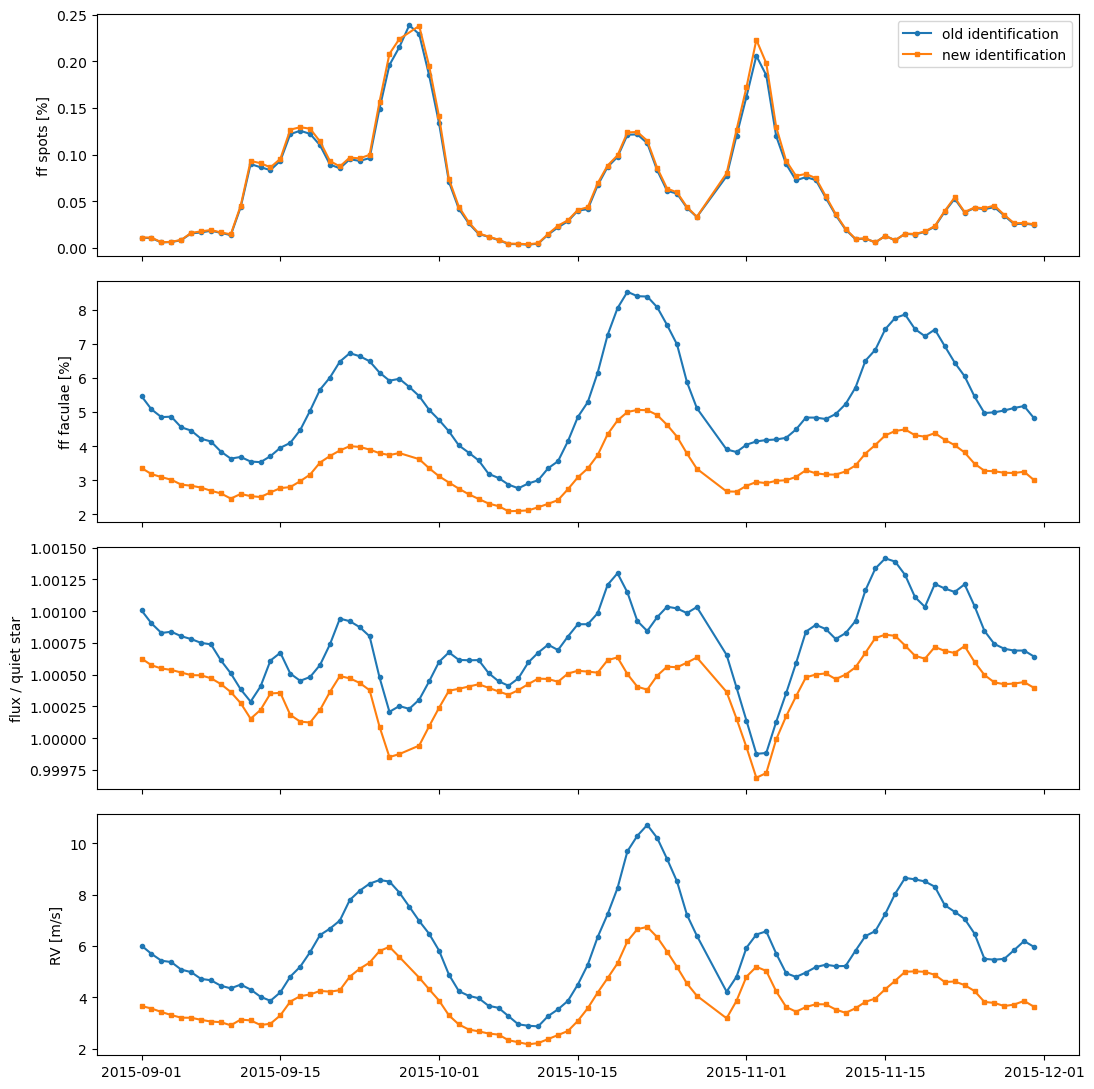

,old (mean),new (mean),old (max - min),new (max - min),correlation
ff_sp,0.0633,0.06591,0.2253,0.2338,0.9997
ff_fc,5.233,3.33,5.77,2.974,0.9931
lc,1.001,1,0.001538,0.001126,0.9343
rv,5.995,3.975,7.849,4.573,0.9626
fwhm,6526,6524,6.89,4.385,0.9709
bis,-42.23,-42.82,3.152,2.11,0.8382


In [3]:
case = tov.case('sdo_2015', 'SDO maps of 2015-09-01 to 2015-12-01', regions=None, times=None,
                conf={'general': {'spectral_library': 'mps'}, 'spots': {'sdo_input': 1, 'SDO_input_path': NEW_MAPS + '/'}})
conf_new = tov.write_conf(case)                    # the configuration (tests/old_version/reference/sdo_2015.conf)
obs = ['lc', 'rv', 'fwhm', 'bis', 'contrast']
sim_new = simulate_old_config(conf_new, observables=obs, old_package=tov.OLD_PACKAGE, verbose=False)
sim_old_maps = simulate_old_config(conf_new, observables=obs, old_package=tov.OLD_PACKAGE, verbose=False,
                                   paths={'sdo_folder': str(OLD_MAPS)})

def by_date(sim, dates):
    return pd.DataFrame({k: sim[k] for k in ('ff_sp', 'ff_fc', 'lc', 'rv', 'fwhm', 'bis')}, index=pd.to_datetime(dates))
new = by_date(sim_new, new_id['dates'])
old = by_date(sim_old_maps, old_dates)
both = new.join(old, lsuffix='_new', rsuffix='_old', how='inner')

fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
for ax, (k, label) in zip(axes, (('ff_sp', 'ff spots [%]'), ('ff_fc', 'ff faculae [%]'), ('lc', 'flux / quiet star'), ('rv', 'RV [m/s]'))):
    ax.plot(old.index, old[k], 'o-', ms=3, label='old identification')
    ax.plot(new.index, new[k], 's-', ms=3, label='new identification')
    ax.set_ylabel(label)
axes[0].legend()
plt.tight_layout()
plt.show()

summary = pd.DataFrame({k: {'old (mean)': both[k + '_old'].mean(), 'new (mean)': both[k + '_new'].mean(),
                            'old (max - min)': np.ptp(both[k + '_old']), 'new (max - min)': np.ptp(both[k + '_new']),
                            'correlation': np.corrcoef(both[k + '_old'], both[k + '_new'])[0, 1]}
                        for k in ('ff_sp', 'ff_fc', 'lc', 'rv', 'fwhm', 'bis')}).T
pd.options.display.float_format = '{:.4g}'.format
summary

## 3. Old StarSim against SunSim, on the new maps

The old StarSim runs once on the new maps (in its environment, `old_python`, through `tests/old_version/run_old_starsim.py`). SunSim runs with the old physics (`reproduce_old_bugs=True`: the outputs must coincide) and with its own (the known differences). Largest difference and amplitude of every output.

In [4]:
old_code, _ = tov.old_results(case, refresh=True)
sunsim_old_physics = simulate_old_config(conf_new, observables=obs, old_package=tov.OLD_PACKAGE, reproduce_old_bugs=True,
                                         verbose=False)
rows = []
for k in ('ff_sp', 'ff_fc', 'lc', 'rv', 'fwhm', 'bis', 'contrast'):
    a = np.asarray(old_code[k], dtype=float)
    rows.append({'output': k, 'old StarSim (max - min)': np.ptp(a),
                 'max |old - SunSim, old physics|': np.max(np.abs(a - sunsim_old_physics[k])),
                 'max |old - SunSim|': np.max(np.abs(a - sim_new[k]))})
pd.options.display.float_format = '{:.3g}'.format
pd.DataFrame(rows).set_index('output')

,old StarSim (max - min),"max |old - SunSim, old physics|",max |old - SunSim|
output,,,
ff_sp,0.235,0,0.00156
ff_fc,2.99,0,0.0252
lc,0.00113,4.66e-15,8.35e-06
rv,4.57,8.26e-07,0.0221
fwhm,4.39,1.57e-05,2.5
bis,2.1,6.59e-12,0.112
contrast,0.00156,1.19e-09,1.07e-05


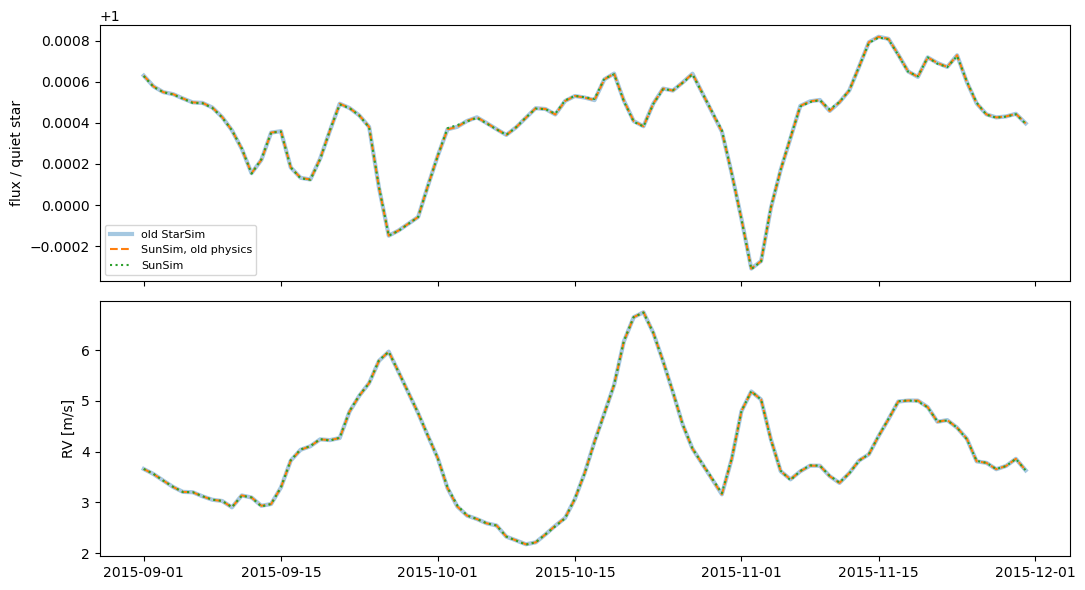

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
t = new.index
for ax, k, label in ((axes[0], 'lc', 'flux / quiet star'), (axes[1], 'rv', 'RV [m/s]')):
    ax.plot(t, old_code[k], '-', lw=3, alpha=0.4, label='old StarSim')
    ax.plot(t, sunsim_old_physics[k], '--', label='SunSim, old physics')
    ax.plot(t, sim_new[k], ':', label='SunSim')
    ax.set_ylabel(label)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Time and RAM

Each code runs the same simulation on the new maps (light curve + RV, FWHM, BIS, contrast; 15 rings) in a **new process**, imports and reading of the maps included, under `/usr/bin/time -l` (wall time and peak resident memory of the process). The old StarSim reads the text maps with `np.loadtxt` and keeps all of them in memory; SunSim reads them a few at a time. SunSim is run twice: on the text maps, and on the same maps as `.npy` (`make_sdo_maps(..., fmt='npy')`, the default).

In [6]:
def timed(cmd, env=None):
    """Wall time [s] and peak RSS [MB] of a command (macOS /usr/bin/time -l)."""
    t = time.perf_counter()
    p = subprocess.run(['/usr/bin/time', '-l'] + cmd, capture_output=True, text=True, env=env)
    dt = time.perf_counter() - t
    if p.returncode != 0:
        raise RuntimeError(p.stderr[-2000:])
    rss = int(re.search(r'(\d+)\s+maximum resident set size', p.stderr).group(1)) / 1e6        # bytes on macOS
    return dt, rss

# old StarSim: the runner of the tests (its environment, its caches)
job = os.path.join(WORK, 'old_job.json')
json.dump({'old_package': str(tov.OLD_PACKAGE), 'conf': str(conf_new), 'out': os.path.join(WORK, 'old_timed.npz'),
           'times': None, 'observables': obs, 'regions': None, 'patch': None}, open(job, 'w'))
env = dict(os.environ, PYTHONPYCACHEPREFIX=os.path.join(WORK, 'pycache'), NUMBA_CACHE_DIR=os.path.join(WORK, 'numba'),
           MPLBACKEND='Agg')
runs = {'old StarSim (text maps)': timed([tov.OLD_PYTHON, os.path.join(REPO, 'tests', 'old_version', 'run_old_starsim.py'), job], env)}

# SunSim: simulate_old_config in a new process (its own environment), text maps and .npy maps
NPY_MAPS = os.path.join(WORK, 'new_maps_npy')
sdo.make_sdo_maps(HMI, NPY_MAPS, START, END, size=1024, epoch='index', fmt='npy', verbose=False)
script = os.path.join(WORK, 'run_sunsim.py')
open(script, 'w').write("""import sys
from sunsim import simulate_old_config
simulate_old_config(sys.argv[1], observables=%r, old_package=sys.argv[2], paths={'sdo_folder': sys.argv[3]}, verbose=False)
""" % obs)
sunsim_python = str(local_path('sunsim_python', default=sys.executable))
for label, folder in (('SunSim (text maps)', NEW_MAPS), ('SunSim (.npy maps)', NPY_MAPS)):
    timed([sunsim_python, script, str(conf_new), str(tov.OLD_PACKAGE), folder], env)       # first run: Numba cache
    runs[label] = timed([sunsim_python, script, str(conf_new), str(tov.OLD_PACKAGE), folder], env)

t_old = runs['old StarSim (text maps)'][0]
pd.options.display.float_format = '{:.3g}'.format
pd.DataFrame([{'version': k, 'time [s]': v[0], 'peak RAM [MB]': v[1], 'speed-up': t_old / v[0]} for k, v in runs.items()]).set_index('version')

,time [s],peak RAM [MB],speed-up
version,,,
old StarSim (text maps),371,1.75e+03,1
SunSim (text maps),11,708,33.9
SunSim (.npy maps),1.18,389,316


**Results** (88 days of 2015-09-01 to 2015-11-30; 2015-09-28, 10-28 and 10-29 skipped: 09-28 could not be read from the cloud folder, 10-28 and 10-29 have no image, as in the old maps)

* **Old and new identification.** The spots hardly change: ff_sp correlates to 0.9997 with the old one, 4 % larger on average (0.066 against 0.063 % of the disc). The **faculae are ~35 % smaller** (mean ff_fc 3.3 % against 5.2 %, amplitude 3.0 against 5.8 %), with the same time variation (correlation 0.993): the noise threshold is now applied (8 G x 1024/4096 = 2 G; with `int()` it was 0) and μ is cos θ. As a consequence the light curve varies less (amplitude 0.11 % against 0.15 %) and so does the RV (mean 4.0 against 6.0 m/s, amplitude 4.6 against 7.8 m/s); the shapes stay close (correlation 0.93 for the light curve, 0.96 for the RV).
* **Old StarSim against SunSim on the new maps.** With the old physics (`reproduce_old_bugs=True`) SunSim gives the outputs of the old StarSim: filling factors identical, light curve to 5e-15, RV to 7e-7 m/s, FWHM to 2e-5 m/s, BIS to 7e-12 m/s. With the physics of SunSim the light curve differs by 8e-6, the RV by 0.02 m/s and the FWHM by 2.5 m/s, the known differences (MURaM limb below μ = 0.1, projection of the pixels, spots over faculae in every pixel).
* **Time and RAM** (88 epochs, 944 x 944 maps, light curve + RV, FWHM, BIS, contrast, 15 rings; new process): the old StarSim 223 s and 1.6 GB; SunSim 12.8 s and 0.69 GB on the same text maps (17x faster, most of the time reading the text files), 1.8 s and 0.40 GB on the `.npy` maps written by `make_sdo_maps` by default (**122x faster**).